<center>

###### Signals & Systems
## Project - Phase 2
### Mahan Zamani(402101877) - Sina Hashemi(402102668)

---

---

---

## 1 Project Description and Theoretical Questions

### 1.1 Introduction to License Plate Recognition (LPR)

#### 1.1.1 Two-Dimensional Correlation

##### 1. What is the mathematical definition of correlation between two signals? Explain it in your own words and write the standard formula. What does the correlation value represent?

In this project, we use **Pearson correlation**, which measures how similar the **shape** of two signals is, regardless of their brightness or scale. It tells us whether two patterns rise and fall together (positive correlation), in opposite directions (negative), or have no relation at all (zero).

This type of correlation is **normalized**, meaning it always falls between –1 and +1:

* +1: Perfect match
* 0: No similarity
* –1: Perfect opposite

It is more reliable than raw cross-correlation for comparing image segments, because it eliminates the effect of constant brightness or low contrast.

**Formula:**:
Given two signals $x[n]$ and $y[n]$ of length $N$:

$$
\text{Corr}(x, y) = \frac{\sum_{n=0}^{N-1} (x[n] - \mu_x)(y[n] - \mu_y)}{\sqrt{\sum (x[n] - \mu_x)^2} \cdot \sqrt{\sum (y[n] - \mu_y)^2}}
$$

Where:

* $\mu_x$: mean of signal $x$
* $\mu_y$: mean of signal $y$
* The result lies in the range $[-1, 1]$

This method works well for **pattern matching**, even if the overall intensity (brightness) of the image changes, which is useful in real-world conditions.

---

##### 2. Research and explain how a method designed for one-dimensional signals can be used to compare images or image segments. Describe your proposed approach clearly. (Do not explain 2D correlation.)

Although images are 2D, we can apply 1D Pearson correlation in two passes — first across rows, then across columns — to compute similarity without using 2D correlation.

Here's a step-by-step method:

1. Ensure the **template image** (e.g., character ‘A’) and the **target image** (license plate character segment) are the same size: $N \times M$.
2. Normalize both to grayscale and resize/crop if needed.
3. For each row $i \in [0, N-1]$:
  * Extract row vectors:
    $x_i = \text{template}[i, :]$
    $y_i = \text{target}[i, :]$
  * Compute **Pearson correlation** between $x_i$ and $y_i$.
  * Store the result as $r_{\text{row}}[i]$
4. Compute the **average of all row-wise correlation values**:
$$
\text{score}_{\text{row}} = \frac{1}{N} \sum_{i=0}^{N-1} r_{\text{row}}[i]
$$
5. For each column $j \in [0, M-1]$:
  * Extract column vectors:
    $x_j = \text{template}[:, j]$
    $y_j = \text{target}[:, j]$
  * Compute **Pearson correlation** between $x_j$ and $y_j$.
  * Store the result as $r_{\text{col}}[j]$
6. Compute the **average of all column-wise correlation values**:
$$
\text{score}_{\text{col}} = \frac{1}{M} \sum_{j=0}^{M-1} r_{\text{col}}[j]
$$
7. Combine both row and column scores using a weighted average:
$$
\text{final score} = \frac{\text{score}_{\text{row}} + \text{score}_{\text{col}}}{2}
$$

This method compares both **horizontal and vertical patterns** using only 1D correlation. It is more sensitive to noise, rotation, and misalignment than full 2D correlation, but it's computationally simpler.

---

#### 1.1.2 Image Blurring and Degradation Modeling

##### 1. Explain how this 1D filter is applied to images, and also explain the parameter p and its effect on the filter's performance.

$$H_{blur} = \frac{1 - p}{1 - p z^{-1}}$$

**Filter Properties:**

- Type: Infinite Impulse Response (IIR)  
- Frequency Response: Low-pass
- zeros & poles: one zero at 0 one pole at p 

**Impact on the Spatial Domain:**

The filter operates using the following recurrence relation:  
$$ y[n] = (1 - p) x[n] + p y[n-1] $$  

**Observed Effect on the Image:**

The filter introduces **motion blur**, which aligns with theoretical expectations:  
- Low-pass filters blur images by attenuating high-frequency details  
- The equation shows each pixel's intensity depends on its previous value, mimicking motion blur's temporal propagation  

**Impact of Parameter p:**

When analyzing the pole-zero plot:  
- The filter has a single pole on the unit circle  
- As p increases:  
  - The pole moves closer to the unit circle  
  - Low-pass effect intensifies  
  - Image blurring becomes stronger

**Filter Application on Images:**

Since the filter is one-dimensional (1D), it cannot be directly applied to a 2D image. However, it can be applied either row-wise or column-wise.

---

##### 2. If we assume that we have the blur transformation function (blur kernel) of the channel, can we recover a high-quality and clean image? Why?

**The Problem: Naive Deconvolution Fails**

Given a blurry image y, blur kernel h, and noise n, the true image x satisfies:
$$
y = h * x + n
$$
where * denotes convolution.

The naive solution $$ X = Y / H $$ (in Fourier domain) fails because:
1. Zeros in  H : Division by zero causes instability.
2. Noise Amplification: N / H corrupts the estimate.


**Wiener Deconvolution: Theory**

The Wiener filter minimizes the Mean Squared Error (MSE) between X and its estimate X'.

**Frequency-Domain Formula**

$$
\hat{X} = \left[ \frac{H^*}{|H|^2 + NSR} \right] Y
$$
- H*: Complex conjugate of blur kernel H.
- NSR: Noise-to-signal ratio.

---

#### 1.1.3 Sampling Rate and Resolution Effects

##### 1. Do a bit of research on 2D sampling theory and briefly summarize your understanding.

2D sampling theory extends the principles of Nyquist-Shannon sampling theory from 1D signals (e.g., audio) to 2D signals (e.g., images). The key idea is that a continuous 2D signal (like an optical image) must be sampled at a sufficient rate to avoid aliasing (distortion caused by undersampling).

---

---

## 2 Implementation

In [1]:
import os
import cv2
import numpy as np
from scipy import fftpack
import matplotlib.pyplot as plt

### 2.1 Ideal Case – Controlled Environment

#### 2.1.1. Write a function that takes a license plate image as input and split the image into its individual characters (both digits and letters). Plot each segmented character.

In [2]:
def segment_characters(plate_image_path):
    """
    Segments characters from a license plate image.

    Parameters:
    plate_image_path (str/np.array): File path OR preloaded grayscale image

    Returns:
    list: Grayscale character images (80x40 numpy arrays)
    """

    # Step 1: Load and convert to grayscale
    try:
        image = cv2.imread(plate_image_path)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    except Exception as e:
        # To support the second part of the program
        image = plate_image_path
        gray = image

    # Step 2: Threshold the image to binary
    # characters(dark) -> white, background(light) -> black
    mean_val = np.mean(gray)
    binary = np.where(gray > mean_val, 0, 255).astype(np.uint8)

    # Step 3: Remove borders and blue area on the left
    # We'll skip the first 15% of columns to avoid EU symbol and blue strip
    binary[:, :int(0.15 * binary.shape[1])] = 0

    # Step 4: Use contours to find character regions
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Step 5: Filter and sort bounding boxes (only keep likely characters)
    char_boxes = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        aspect_ratio = h / w
        if 0.5 < aspect_ratio < 5 and h > 0.4 * binary.shape[0]:  # likely a character
            char_boxes.append((x, y, w, h))

    # Sort left to right
    char_boxes = sorted(char_boxes, key=lambda b: b[0])

    # Step 6: Extract character images
    characters = []
    for x, y, w, h in char_boxes:
        char_img = gray[y-4:y+h+4, x-4:x+w+4]
        char_img = cv2.resize(char_img, (40, 80))  # Ensure size matches templates
        characters.append(char_img)

    return characters

The `segment_characters` function uses `cv2.imread` to load the image from a file path and `cv2.cvtColor(..., cv2.COLOR_BGR2GRAY)` to convert the image from BGR (color) to grayscale.

Then, it calculates the mean pixel value of the grayscale image. The function converts bright areas (assumed to be background) to black (0), and darker regions (characters) to white (255).
This manual thresholding method is useful when adaptive methods fail due to uniform lighting or embossing.

After removing leftmost 15% of the image, it finds contours of character regions.
- `cv2.findContours`: Detects contours (closed shapes) in the binary image.
- `cv2.RETR_EXTERNAL`: Only retrieves external contours (ignores nested ones).
- `cv2.CHAIN_APPROX_SIMPLE`: Compresses horizontal, vertical, and diagonal segments to save memory.

After filtering out contours that are too small or have unrealistic shape (like noise), Characters are then sorted from left to right using the `x` coordinate.

Each character is cropped from the original grayscale image with a 4-pixel padding to preserve borders. Then resized to 40×80 pixels to match the reference template size.

Text(0.5, 0.98, 'Segmented Characters')

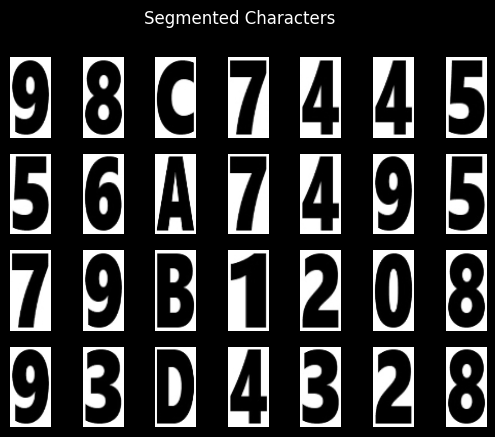

In [3]:
idealCharsList = []

for i in range(4):
    idealCharsList.append(segment_characters(f"../ideal/p{i+1}.jpg"))

fig1, ax = plt.subplots(4, 7)
for i in range(4):
        for j in range(len(idealCharsList[i])):
            ax[i][j].imshow(idealCharsList[i][j], cmap='gray')
            ax[i][j].axis('off')
fig1.suptitle('Segmented Characters')

#### 2.1.2. Now, using the provided technique, recognize each character and print the final license plate as output. Make sure to report the correlation value obtained for character recognition.(Do this for all the license plates in "ideal" folder.)

In [4]:
def pearson_corr(x, y):
    """
    Computes an averaged Pearson correlation between two 2D arrays (images)
    by applying 1D correlation row-wise and column-wise.

    Parameters:
    x (np.array): First grayscale image
    y (np.array): Second grayscale image

    Returns:
    float: Averaged correlation value
    """
    x = x.astype(np.float32)
    y = y.astype(np.float32)

    row_corrs = []
    for i in range(x.shape[0]):  # for each row
        r1 = x[i, :]
        r2 = y[i, :]
        if np.std(r1) == 0 or np.std(r2) == 0:
            corr = 0
        else:
            corr = np.corrcoef(r1, r2)[0, 1]
        row_corrs.append(corr)

    col_corrs = []
    for j in range(x.shape[1]):  # for each column
        c1 = x[:, j]
        c2 = y[:, j]
        if np.std(c1) == 0 or np.std(c2) == 0:
            corr = 0
        else:
            corr = np.corrcoef(c1, c2)[0, 1]
        col_corrs.append(corr)

    # Combine row and column correlations
    all_corrs = row_corrs + col_corrs
    return np.mean(all_corrs)


def load_templates(folder):
    """
    Loads all character templates from a folder and resizes them.

    Parameters:
    folder (str): Path to a folder containing character images

    Returns:
    dict: Dictionary mapping character labels (str) to grayscale images (np.array)
    """
    templates = {}

    for filename in os.listdir(folder):
        if filename.endswith(".jpg"):
            label = os.path.splitext(filename)[0]  # Extract character label from filename
            img = cv2.imread(os.path.join(folder, filename), cv2.IMREAD_GRAYSCALE)
            img = cv2.resize(img, (40, 80))  # Normalize size
            templates[label] = img

    return templates

def recognize_plate(char_images, letters_path="../letters", numbers_path="../numbers"):
    """
    Recognizes a sequence of characters from a list of segmented character images.

    Parameters:
    char_images (list): List of 40x80 grayscale images of individual characters
    letters_path (str): Path to folder containing letter templates
    numbers_path (str): Path to folder containing digit templates

    Returns:
    tuple:
        - recognized (str): Recognized license plate string
        - correlations (list of dict): Correlation values per character per template
        - bestCorrelations (list of float): Highest correlation for each character
    """
    # Load all templates
    templates = dict()
    templates.update(load_templates(letters_path))
    templates.update(load_templates(numbers_path))

    recognized = ""
    correlations = []      # Full dictionary of correlation values for each character
    bestCorrelations = []  # Only best values for reporting

    for i, char_img in enumerate(char_images):
        charCorr = dict()
        char_img = cv2.resize(char_img, (40, 80))  # Ensure the input char matches template size

        best_char = '?'
        best_corr = -1

        # Compare each character with every template using Pearson correlation
        for label, tmpl_img in templates.items():
            corr = pearson_corr(char_img, tmpl_img)
            charCorr[label] = corr

            if corr > best_corr:
                best_corr = corr
                best_char = label

        recognized += best_char
        correlations.append(charCorr)
        bestCorrelations.append(best_corr)

    return recognized, correlations, bestCorrelations


In [5]:
for i in range(4):
    recognized, corr_vals, best_corrs = recognize_plate(idealCharsList[i])
    print(recognized)
    print("Best Correlations: ", best_corrs)
    print("All Correlations:")
    for corr_val in corr_vals:
        print(corr_val)

98C7445
Best Correlations:  [0.9061192299115105, 0.9043874793026419, 0.9157060409047278, 0.9157735057407074, 0.9414255362599449, 0.9227800565784415, 0.8995899987246314]
All Correlations:
{'B': 0.5421406014526868, 'C': 0.16416126491083716, 'A': 0.22293874341053221, 'D': 0.5909924028294132, '8': 0.576040705617693, '9': 0.9061192299115105, '4': 0.19785129327667506, '5': 0.5735391447415542, '7': 0.25519829493572865, '6': 0.491149451223296, '2': 0.33323861835011037, '3': 0.5645932807796361, '1': 0.36356316377895354, '0': 0.6714878034069919}
{'B': 0.727832846987157, 'C': 0.32425311704079307, 'A': 0.2697889858988129, 'D': 0.41560088854110594, '8': 0.9043874793026419, '9': 0.5450588368144623, '4': 0.4335046897330983, '5': 0.5128552585285315, '7': 0.218656085252645, '6': 0.5914640847235446, '2': 0.4365693635174278, '3': 0.5841595823118194, '1': 0.3186995670937262, '0': 0.5973993054823715}
{'B': 0.246470825199943, 'C': 0.9157060409047278, 'A': 0.2125875443066817, 'D': 0.1644178020185253, '8': 0.

#### 2.1.3. In this step, analyze the effect of spatial downsampling (i.e., resolution reduction) on character recognition accuracy.
- Apply downsampling to the license plate image before performing character segmentation and also plot before and after.
- Repeat the character segmentation and recognition process for multiple downsampling rates (e.g., 1/2, 1/4, 1/6, ...).
- For each rate, evaluate whether the characters are still recognizable using your correlation-based method.
- Determine and report the minimum sampling rate at which the license plate is still correctly recognizable.
- Plot or tabulate your findings to show how recognition accuracy changes with sampling rate.
- It is not necessary to include all the processes for all the license plates in "ideal" folder in the report. Therefore, include the processing steps for one license plate image in the report, and only report the final outputs for the remaining license plates .

In [6]:
def downsample(img, factor):
    """
    Downsample by selecting every 'factor'-th pixel.
    """
    downsampled = img[::factor, ::factor]
    return downsampled

for plate 1, Down-Sampling 1/1 We have recognized plate: 98C7445
for plate 1, Down-Sampling 1/2 We have recognized plate: 98C7445
for plate 1, Down-Sampling 1/4 We have recognized plate: 98C7445
for plate 1, Down-Sampling 1/8 We have recognized plate: AAA7A4
for plate 1, Down-Sampling 1/16 We have recognized plate: BBBBBB


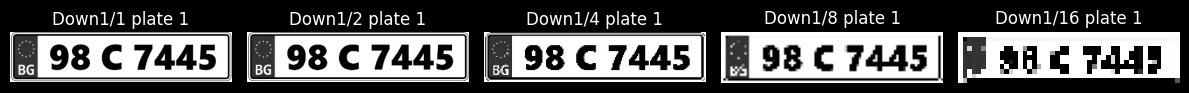

for plate 2, Down-Sampling 1/1 We have recognized plate: 56A7495
for plate 2, Down-Sampling 1/2 We have recognized plate: 56A7495
for plate 2, Down-Sampling 1/4 We have recognized plate: 54A7495
for plate 2, Down-Sampling 1/8 We have recognized plate: 44A7144
for plate 2, Down-Sampling 1/16 We have recognized plate: BBBBBB


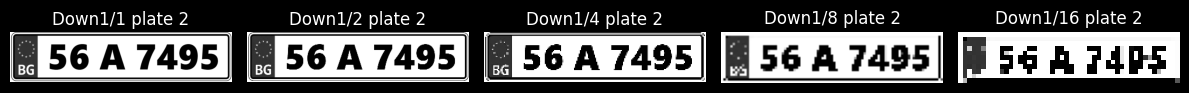

for plate 3, Down-Sampling 1/1 We have recognized plate: 79B1208
for plate 3, Down-Sampling 1/2 We have recognized plate: 79B1208
for plate 3, Down-Sampling 1/4 We have recognized plate: 7981208
for plate 3, Down-Sampling 1/8 We have recognized plate: 7AA4744
for plate 3, Down-Sampling 1/16 We have recognized plate: BBBBB


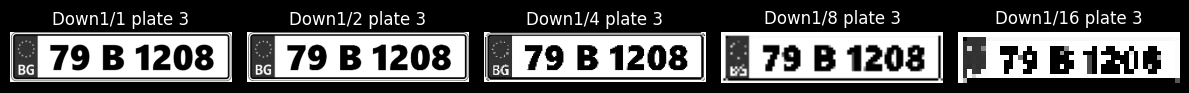

for plate 4, Down-Sampling 1/1 We have recognized plate: 93D4328
for plate 4, Down-Sampling 1/2 We have recognized plate: 93D4328
for plate 4, Down-Sampling 1/4 We have recognized plate: 9304328
for plate 4, Down-Sampling 1/8 We have recognized plate: A7A447A
for plate 4, Down-Sampling 1/16 We have recognized plate: BBBBB


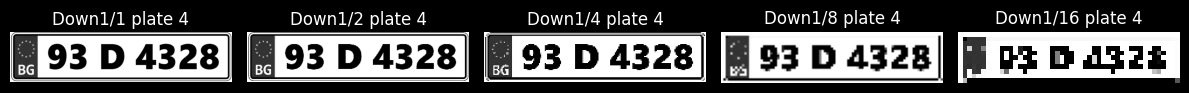

In [7]:
idealPlate1 = cv2.imread('../ideal/p1.jpg', cv2.IMREAD_GRAYSCALE)
idealPlate2 = cv2.imread('../ideal/p2.jpg', cv2.IMREAD_GRAYSCALE)
idealPlate3 = cv2.imread('../ideal/p3.jpg', cv2.IMREAD_GRAYSCALE)
idealPlate4 = cv2.imread('../ideal/p4.jpg', cv2.IMREAD_GRAYSCALE)
idealPlates = [idealPlate1, idealPlate2, idealPlate3, idealPlate4]

for j in range(4):
    plt.figure(figsize=(12, 8))
    for i in range(5):
        temp = downsample(idealPlates[j], 2**i)
        recognized, corr_vals, best_corrs = recognize_plate(segment_characters(temp))
        print(f"for plate {j+1}, Down-Sampling 1/{2**i} We have recognized plate: {recognized}")
        plt.subplot(1, 5, i+1), plt.imshow(temp, cmap='gray'), plt.title(f'Down1/{2**i} plate {j+1}'), plt.axis(False)
    plt.tight_layout()
    plt.show()

Due to experiments result minimum sampling rate which license plates are still recognizable is 1/4.

### 2.2 Realistic Case – Simulated Real-World Conditions

#### 2.2.1. Attempt to extract the license plate characters using the functions from the previous section. Evaluate whether character recognition is successful without any deblurring.

Text(0.5, 0.98, 'Segmented Characters')

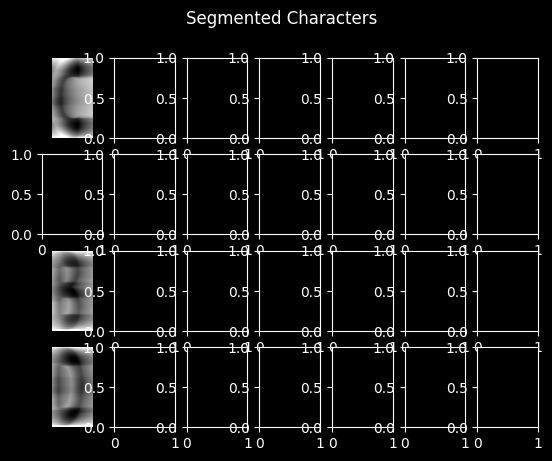

In [8]:
realisticCharsList = []

for i in range(4):
    realisticCharsList.append(segment_characters(f"../realistic/p{i+1}.jpg"))

fig2, ax = plt.subplots(4, 7)
for i in range(4):
        for j in range(len(realisticCharsList[i])):
            ax[i][j].imshow(realisticCharsList[i][j], cmap='gray')
            ax[i][j].axis('off')
fig2.suptitle('Segmented Characters')

In [9]:
for i in range(4):
    recognized, corr_vals, best_corrs = recognize_plate(realisticCharsList[i])
    print(recognized)
    print("Best Correlations: ", best_corrs)

C
Best Correlations:  [0.763668432066349]

Best Correlations:  []
3
Best Correlations:  [0.6216059953835085]
0
Best Correlations:  [0.649577287890637]


As is clear from the results, our function is not capable of reading a real license plate.

#### 2.2.2. Since your answer to the previous section is likely negative, you should now use the available information to extract higher-quality and higher-resolution images. Estimate the optimal value of p and use it to find deblur filter.

As explained in Section 1.1.2, *p* represents the intensity of the filter. A higher value of *p* (where 0 < *p* < 1) results in a more blurred image during filtering, while during deblurring, a higher *p* value leads to a higher-quality recovered image.

Based on experimental results, *p* = 0.99 has been found to be an optimal value for achieving high-quality image recovery. However, it is important to note that setting *p* too close to 1 (or exceeding reasonable limits) can introduce excessive distortion, negatively affecting the output. Therefore, values should be carefully chosen to balance clarity and artifacts.

#### 2.2.3. The blur in the provided license plate images is modeled using a one-dimensional linear filter. As discussed earlier, such filters can be applied to two-dimensional images in horizontal and vertical directions. Apply the filter you obtained in the previous section (with the estimated optimal parameter p) to deblur the image. Plot and save the deblurred images. Select the clearest version for further processing.

[ WARN:0@153.763] global loadsave.cpp:848 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.


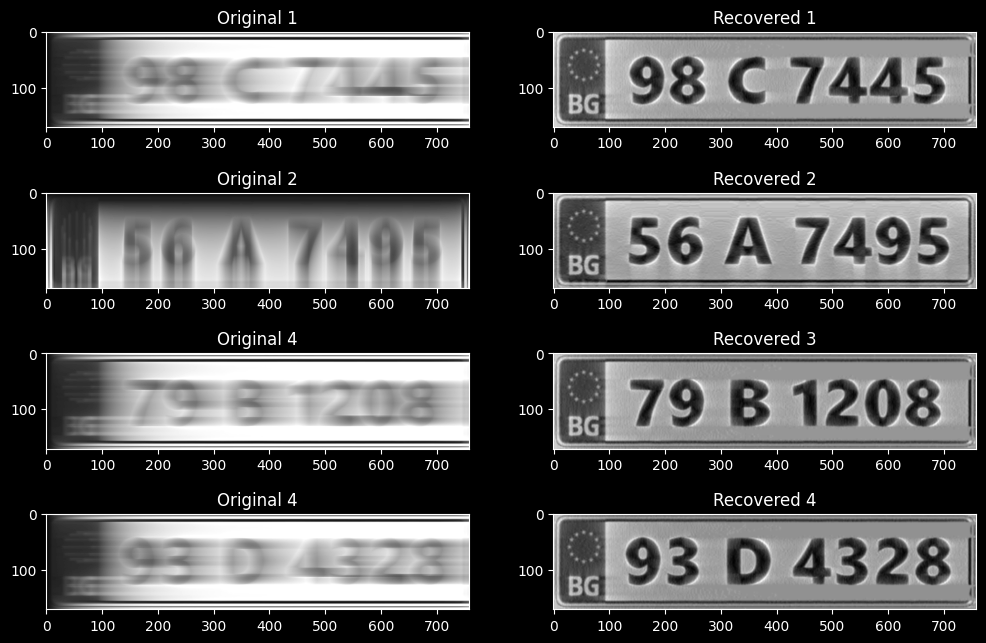

In [10]:
def recover_motion_blurry_img(img, p=0.99, direction='right'):
    """
    Recover a motion-blurred image with specified direction.

    Parameters:
    - img: Input blurred image (grayscale)
    - p: Blur parameter (0 < p < 1)
    - direction: Blur direction ('left', 'right', 'up', 'down')
    """
    img = img.astype(np.float32) / 255.0  # Convert to float32 and normalize

    org_M, org_N = img.shape

    # Determine padding based on direction
    if direction in ('left', 'right'):
        c = org_N
        paddedImg = cv2.copyMakeBorder(img, 0, 0, c, c, cv2.BORDER_REPLICATE)
    else:  # up or down
        c = org_M
        paddedImg = cv2.copyMakeBorder(img, c, c, 0, 0, cv2.BORDER_REPLICATE)

    M, N = paddedImg.shape

    # Create the appropriate filter based on direction
    if direction in ('left', 'right'):
        u = np.arange(N)
        omega = 2 * np.pi * u / N
        if direction == 'right':
            H = (1 - p) / (1 - p * np.exp(-1j * omega))
        else:  # left
            H = (1 - p) / (1 - p * np.exp(1j * omega))
        H = np.tile(H, (M, 1))
    else:  # up or down
        v = np.arange(M)
        omega = 2 * np.pi * v / M
        if direction == 'down':
            H = (1 - p) / (1 - p * np.exp(-1j * omega))
        else:  # up
            H = (1 - p) / (1 - p * np.exp(1j * omega))
        H = np.tile(H, (N, 1)).T  # Transpose for column-wise operation

    # Frequency domain processing
    G = fftpack.fft2(paddedImg)
    F_est = G / H
    deblurred_image = np.real(fftpack.ifft2(F_est))

    # Crop to original size
    if direction in ('left', 'right'):
        deblurred_image = deblurred_image[:, c:c+org_N]
    else:
        deblurred_image = deblurred_image[c:c+org_M, :]

    # Gaussian Filter for cleaner images
    deblurred_image = cv2.GaussianBlur(deblurred_image, (5, 5), 0)

    return deblurred_image

# Example usage
realImg1 = cv2.imread('../realistic/p1.jpg', cv2.IMREAD_GRAYSCALE)
realImg2 = cv2.imread('../realistic/p2.jpg', cv2.IMREAD_GRAYSCALE)
realImg3 = cv2.imread('../realistic/p3.jpg', cv2.IMREAD_GRAYSCALE)
realImg4 = cv2.imread('../realistic/p4.jpg', cv2.IMREAD_GRAYSCALE)

# Process with different directions
recRealImg1 = recover_motion_blurry_img(realImg1, 0.99, 'right')
recRealImg2 = recover_motion_blurry_img(realImg2, 0.99, 'down')
recRealImg3 = recover_motion_blurry_img(realImg3, 0.99, 'right')
recRealImg4 = recover_motion_blurry_img(realImg4, 0.99, 'right')


try:
    os.mkdir("../outputs/")
except Exception as e:
    pass
cv2.imwrite("../outputs/recRealImg1.jpg", cv2.normalize(recRealImg1, None, alpha = 0, beta = 255, norm_type = cv2.NORM_MINMAX, dtype = cv2.CV_32F))
cv2.imwrite("../outputs/recRealImg2.jpg", cv2.normalize(recRealImg2, None, alpha = 0, beta = 255, norm_type = cv2.NORM_MINMAX, dtype = cv2.CV_32F))
cv2.imwrite("../outputs/recRealImg3.jpg", cv2.normalize(recRealImg3, None, alpha = 0, beta = 255, norm_type = cv2.NORM_MINMAX, dtype = cv2.CV_32F))
cv2.imwrite("../outputs/recRealImg4.jpg", cv2.normalize(recRealImg4, None, alpha = 0, beta = 255, norm_type = cv2.NORM_MINMAX, dtype = cv2.CV_32F))


plt.figure(figsize=(12, 8))
plt.subplot(4, 2, 1), plt.imshow(realImg1, cmap='gray'), plt.title('Original 1')
plt.subplot(4, 2, 2), plt.imshow(recRealImg1, cmap='gray'), plt.title('Recovered 1')
plt.subplot(4, 2, 3), plt.imshow(realImg2, cmap='gray'), plt.title('Original 2')
plt.subplot(4, 2, 4), plt.imshow(recRealImg2, cmap='gray'), plt.title('Recovered 2')
plt.subplot(4, 2, 5), plt.imshow(realImg3, cmap='gray'), plt.title('Original 4')
plt.subplot(4, 2, 6), plt.imshow(recRealImg3, cmap='gray'), plt.title('Recovered 3')
plt.subplot(4, 2, 7), plt.imshow(realImg4, cmap='gray'), plt.title('Original 4')
plt.subplot(4, 2, 8), plt.imshow(recRealImg4, cmap='gray'), plt.title('Recovered 4')
plt.show()

#### 2.2.4. Pass the deblurred image to the character recognition function that you implemented in the ideal section. Observe whether the segmented characters are recognizable using the correlation-based method. If the characters are not correctly identified, or the correlation scores are significantly low, Re-examine your deblurring filter design. Adjust the blur parameter p, the direction of filtering, or the method of inverse filtering. Repeat the deblurring and recognition process until satisfactory results are obtained. (Do this for all the license plates in "realistic" folder)

Text(0.5, 0.98, 'Segmented Characters')

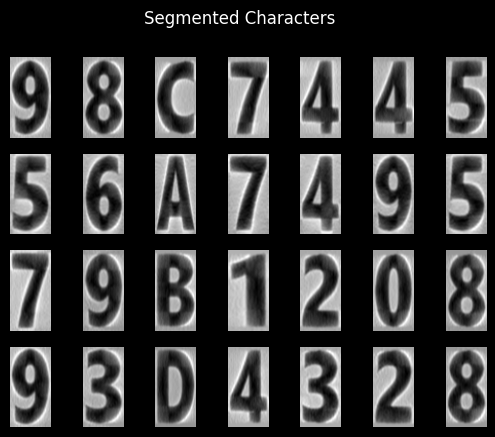

In [11]:
recRealisticCharsList = [recRealImg1, recRealImg2, recRealImg3, recRealImg4]

for i in range(4):
    recRealisticCharsList[i] = segment_characters(recRealisticCharsList[i])

fig3, ax = plt.subplots(4, 7)
for i in range(4):
        for j in range(len(recRealisticCharsList[i])):
            ax[i][j].imshow(recRealisticCharsList[i][j], cmap='gray')
            ax[i][j].axis('off')
fig3.suptitle('Segmented Characters')

In [12]:
for i in range(4):
    recognized, corr_vals, best_corrs = recognize_plate(recRealisticCharsList[i])
    print(recognized)
    print("Best Correlations: ", best_corrs)

98C7445
Best Correlations:  [0.7741879105549903, 0.7698171015016484, 0.7920476368897801, 0.7665736582854924, 0.8100867703114017, 0.7939748544393275, 0.7922494259636604]
56A7495
Best Correlations:  [0.7848640523084403, 0.7616657159432715, 0.8049791693315813, 0.748966533438102, 0.7886089757084048, 0.7682454470614227, 0.7782710458918913]
79B1208
Best Correlations:  [0.7827092976466995, 0.765535518381507, 0.7659803981066926, 0.7943033115622087, 0.7942832935362648, 0.7908110990571771, 0.7850763670648767]
93D4328
Best Correlations:  [0.7811358922750583, 0.7670252661428992, 0.7751990315964501, 0.7897504819016125, 0.791777837792712, 0.7874969278615346, 0.7901178164546382]


#### 2.2.5. In this step, analyze the effect of spatial downsampling (i.e., resolution reduction) on character recognition accuracy.
- Apply downsampling to the license plate image before performing character segmentation and also plot before and after.
- Repeat the character segmentation and recognition process for multiple downsampling rates (e.g., 1/2, 1/4, 1/6, ...).
- For each rate, evaluate whether the characters are still recognizable using your correlation-based method.
- Determine and report the minimum sampling rate at which the license plate is still correctly recognizable.
- Plot or tabulate your findings to show how recognition accuracy changes with sampling rate.
- It is not necessary to include all the processes for all the license plates in "realistic" folder in the report. Therefore, include the processing steps for one license plate image in the report, and only report the final outputs for the remaining license plates.

for plate 1, Down-Sampling 1/1 We have recognized plate: 98C7445
for plate 1, Down-Sampling 1/2 We have recognized plate: 98C7445
for plate 1, Down-Sampling 1/4 We have recognized plate: AA
for plate 1, Down-Sampling 1/8 We have recognized plate: 4
for plate 1, Down-Sampling 1/16 We have recognized plate: 


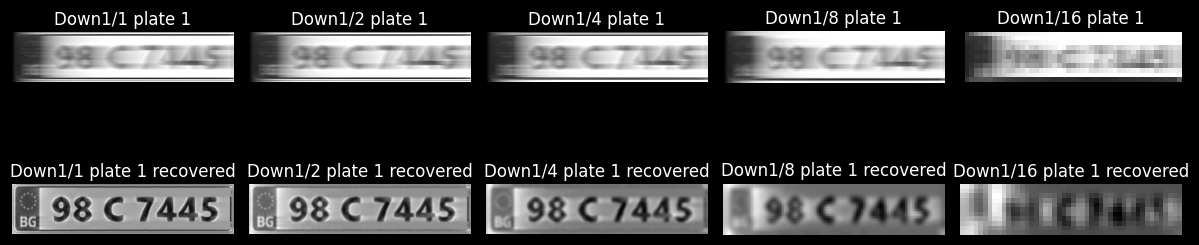

for plate 2, Down-Sampling 1/1 We have recognized plate: 56A7495
for plate 2, Down-Sampling 1/2 We have recognized plate: 567495
for plate 2, Down-Sampling 1/4 We have recognized plate: 
for plate 2, Down-Sampling 1/8 We have recognized plate: 
for plate 2, Down-Sampling 1/16 We have recognized plate: 


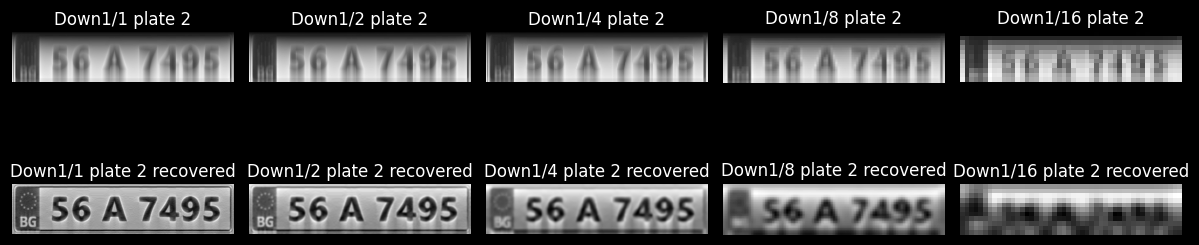

for plate 3, Down-Sampling 1/1 We have recognized plate: 79B1208
for plate 3, Down-Sampling 1/2 We have recognized plate: 7981208
for plate 3, Down-Sampling 1/4 We have recognized plate: 7A
for plate 3, Down-Sampling 1/8 We have recognized plate: 1
for plate 3, Down-Sampling 1/16 We have recognized plate: 


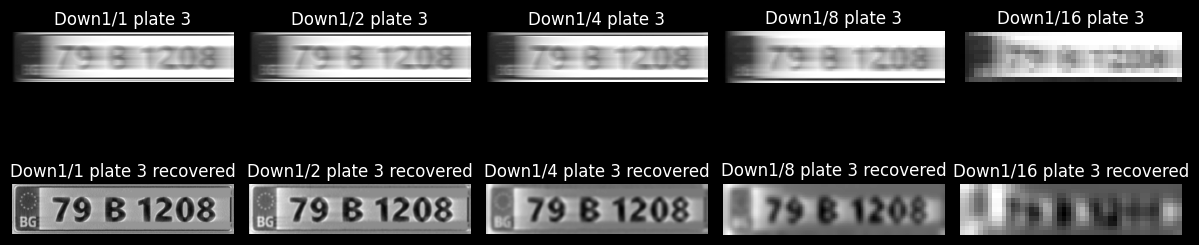

for plate 4, Down-Sampling 1/1 We have recognized plate: 93D4328
for plate 4, Down-Sampling 1/2 We have recognized plate: 93D4328
for plate 4, Down-Sampling 1/4 We have recognized plate: AA
for plate 4, Down-Sampling 1/8 We have recognized plate: 4
for plate 4, Down-Sampling 1/16 We have recognized plate: 


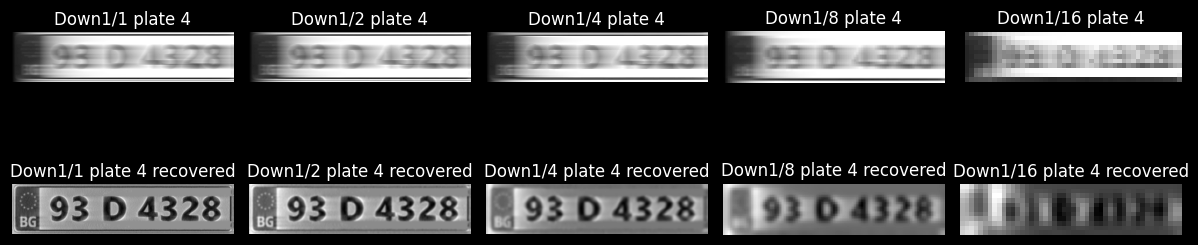

In [13]:
realPlates = [realImg1, realImg2, realImg3, realImg4]
side = ["right", "down", "right", "right"]

for j in range(4):
    plt.figure(figsize=(12, 4))
    for i in range(5):
        temp = downsample(realPlates[j], 2**i)
        tempRecover = recover_motion_blurry_img(temp, 0.99, side[j])
        recognized, corr_vals, best_corrs = recognize_plate(segment_characters(tempRecover))
        print(f"for plate {j+1}, Down-Sampling 1/{2**i} We have recognized plate: {recognized}")
        plt.subplot(2, 5, i+1), plt.imshow(temp, cmap='gray'), plt.title(f'Down1/{2**i} plate {j+1}'), plt.axis(False)
        plt.subplot(2, 5, i+6), plt.imshow(tempRecover, cmap='gray'), plt.title(f'Down1/{2**i} plate {j+1} recovered'), plt.axis(False)
    plt.tight_layout()
    plt.show()

Due to experiments result minimum sampling rate which license plates are still recognizable is 1/2.

#### 2.2.6. In "noisy" folder, there are 2 noisy license plate images. You are asked to determine, without writing any new code (using only existing functions and code), which of these images contains higher-frequency noise content. Provide a convincing justification for your answer.

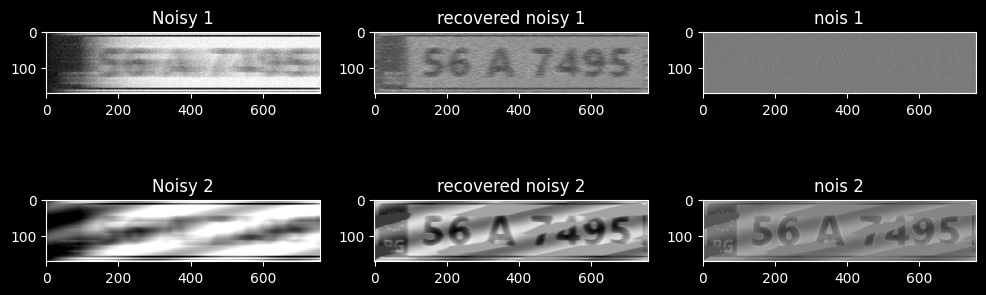

In [14]:
def recover_noisy_motion_blurry_img(img, p=0.99, NSR=0.001):

    img = img.astype(np.float32) / 255.0 # turning unit8 to float32 then normalizing it.

    org_M, org_N = img.shape
    c = org_N
    paddedImg = cv2.copyMakeBorder(img, 0, 0, c, c, cv2.BORDER_REPLICATE)
    M, N = paddedImg.shape

    u = np.arange(N)
    omega_x = 2 * np.pi * u / N
    H_x = (1 - p) / (1 - p * np.exp(-1j * omega_x))

    H = np.tile(H_x, (M, 1))
    G = fftpack.fft2(paddedImg)
    H_conj = np.conj(H)
    F_est = (G * H_conj) / (np.abs(H)**2 + NSR)
    deblurred_image = np.real(fftpack.ifft2(F_est))
    deblurred_image2 = deblurred_image[:, c:c+org_N]
    return deblurred_image2

noisyImg1 = cv2.imread('../noisy/n1.jpg', cv2.IMREAD_GRAYSCALE)
noisyImg2 = cv2.imread('../noisy/n2.jpg', cv2.IMREAD_GRAYSCALE)
recNoisyImg1 = recover_noisy_motion_blurry_img(noisyImg1,0.99,0.01)
recNoisyImg2 = recover_noisy_motion_blurry_img(noisyImg2,0.99,0.001)
nois1 = recover_noisy_motion_blurry_img(noisyImg1,0.99,0)
nois2 = recover_noisy_motion_blurry_img(noisyImg2,0.99,0)


plt.figure(figsize=(12, 4))
plt.subplot(2, 3, 1), plt.imshow(noisyImg1, cmap='gray'), plt.title('Noisy 1')
plt.subplot(2, 3, 2), plt.imshow(recNoisyImg1, cmap='gray'), plt.title('recovered noisy 1')
plt.subplot(2, 3, 4), plt.imshow(noisyImg2, cmap='gray'), plt.title('Noisy 2')
plt.subplot(2, 3, 5), plt.imshow(recNoisyImg2, cmap='gray'), plt.title('recovered noisy 2')
plt.subplot(2, 3, 3), plt.imshow(nois1, cmap='gray'), plt.title('nois 1')
plt.subplot(2, 3, 6), plt.imshow(nois2, cmap='gray'), plt.title('nois 2')
plt.show()

To achieve a clearly recognizable license plate image, we used a Noise-to-Signal Ratio (NSR) of 0.01 for the first image and 0.001 for the second. The higher quality of the second image suggests that the first image contained more noise.

Further confirmation comes from applying a high-frequency filter with NSR = 0 to both images. The first image retained significantly more noise, indicating the presence of higher-frequency noise components compared to the second.

---